# NSGA-II & NSGA-II-FH — Multi-Objective Hardware-Aware NAS

**Objectives**: Maximize test accuracy · Minimize inference latency  
**Search space**: NAS-Bench-201 (15 625 unique CNN architectures)  
**Benchmarks**: HW-NAS-Bench (O(1) lookups, no training cost)  
**Algorithms**:
- **NSGA-II** — standard baseline (population Pareto front only)
- **NSGA-II-FH** — NSGA-II + Fixed-Hypergrid external archive (Patil 2020)

The external archive accumulates *every* non-dominated solution ever visited, yielding a significantly richer Pareto front without extra function evaluations.


## 0 · Configuration

In [2]:
import numpy as np

# ── Paths ─────────────────────────────────────────────────────────────────────
HW_NAS_ROOT   = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project\HW-NAS-Bench"
HW_NAS_PICKLE = f"{HW_NAS_ROOT}/HW-NAS-Bench-v1_0.pickle"
ACC_CSV       = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project\data\nasbench201_accuracies.csv"
OUTPUT_ROOT   = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/nsga2_fh_multirun"

# ── Multi-run grid ─────────────────────────────────────────────────────────────
DATASETS     = ["cifar10", "cifar100", "ImageNet16-120"]
HW_PLATFORMS = ["raspi4", "edgegpu", "edgetpu", "pixel3", "eyeriss", "fpga"]
# All 3 × 6 = 18 combinations will be run
RUN_COMBINATIONS = [(ds, hw) for ds in DATASETS for hw in HW_PLATFORMS]

SEED              = 42
SEARCH_SPACE_SIZE = 15_625   # do NOT change

# ── NSGA-II hyper-parameters ──────────────────────────────────────────────────
POP_SIZE       = 100
N_GENERATIONS  = 50
CROSSOVER_PROB = 0.9
MUTATION_PROB  = 0.1
TOURNAMENT_K   = 2

# ── External archive (FH) hyper-parameters ───────────────────────────────────
FH_REF_ACC   = 0.0
FH_REF_LAT   = 0.0
FH_DELTA_ACC = 0.5
FH_DELTA_LAT = 0.5
FH_MAX_CELLS = 2000
FH_MAX_SOLS  = 5

np.random.seed(SEED)
print(f"Multi-run grid : {len(DATASETS)} datasets × {len(HW_PLATFORMS)} devices = {len(RUN_COMBINATIONS)} combinations")
print(f"NSGA-II        : pop={POP_SIZE}, generations={N_GENERATIONS}")
print(f"FH archive     : delta_acc={FH_DELTA_ACC}%, delta_lat={FH_DELTA_LAT}ms")
print(f"Output root    : {OUTPUT_ROOT}")


Multi-run grid : 3 datasets × 6 devices = 18 combinations
NSGA-II        : pop=100, generations=50
FH archive     : delta_acc=0.5%, delta_lat=0.5ms
Output root    : C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/nsga2_fh_multirun


## 1 · Imports & Setup

In [3]:
import sys, os, time
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm import tqdm
from itertools import product as iproduct

sys.path.insert(0, HW_NAS_ROOT)

plt.style.use("seaborn-v0_8-whitegrid")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

print("Python", sys.version)
print("NumPy ", np.__version__)
print("Pandas", pd.__version__)


Python 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
NumPy  2.1.3
Pandas 2.2.3


## 2 · Load HW-NAS-Bench & Accuracy Table (Once)

In [4]:
from hw_nas_bench_api import HWNASBenchAPI as HWAPI

# Load the API once — reused across all dataset/device combos
hw_api = HWAPI(HW_NAS_PICKLE, search_space="nasbench201")

# Load accuracy table once
acc_df = pd.read_csv(ACC_CSV).set_index("arch_index")

print("HW-NAS-Bench API loaded.")
print(f"Accuracy table : {acc_df.shape[0]} architectures × {acc_df.shape[1]} columns")
print(f"Accuracy columns: {[c for c in acc_df.columns if c.startswith('acc_')]}")

# Validate that all requested datasets and platforms exist
for ds in DATASETS:
    col = f"acc_{ds}"
    assert col in acc_df.columns, f"Missing accuracy column: {col}"

sample = hw_api.query_by_index(0, DATASETS[0])
print(f"\nAvailable HW keys (sample): {list(sample.keys())}")
for hw in HW_PLATFORMS:
    key = f"{hw}_latency"
    assert key in sample, f"Missing HW key: {key}"
    
print("\nAll requested datasets and HW platforms validated ✓")


HW-NAS-Bench API loaded.
Accuracy table : 15625 architectures × 3 columns
Accuracy columns: ['acc_cifar10', 'acc_cifar100', 'acc_ImageNet16-120']

Available HW keys (sample): ['edgegpu_latency', 'edgegpu_energy', 'raspi4_latency', 'edgetpu_latency', 'pixel3_latency', 'eyeriss_latency', 'eyeriss_energy', 'eyeriss_arithmetic_intensity', 'fpga_latency', 'fpga_energy', 'average_hw_metric']

All requested datasets and HW platforms validated ✓


## 3 · Utility Functions

In [5]:
# ── Per-combo evaluation helpers ──────────────────────────────────────────────

def get_accuracy(arch_index: int, dataset: str) -> float:
    return float(acc_df.loc[arch_index, f"acc_{dataset}"])

def get_latency(arch_index: int, dataset: str, hw_platform: str) -> float:
    return float(hw_api.query_by_index(arch_index, dataset)[f"{hw_platform}_latency"])

def evaluate(arch_index: int, dataset: str, hw_platform: str):
    """Returns (accuracy, latency) for a given architecture."""
    return get_accuracy(arch_index, dataset), get_latency(arch_index, dataset, hw_platform)


# ── Pareto utilities ───────────────────────────────────────────────────────────

def is_pareto_front(acc_arr, lat_arr):
    n    = len(acc_arr)
    mask = np.ones(n, dtype=bool)
    for i in range(n):
        if not mask[i]:
            continue
        dominated = (
            (acc_arr >= acc_arr[i]) & (lat_arr <= lat_arr[i]) &
            ((acc_arr > acc_arr[i]) | (lat_arr < lat_arr[i]))
        )
        dominated[i] = False
        if dominated.any():
            mask[i] = False
    return mask

def compute_pareto_df(df: pd.DataFrame) -> pd.DataFrame:
    mask = is_pareto_front(df["accuracy"].values, df["latency"].values)
    return df[mask].sort_values("accuracy", ascending=False).reset_index(drop=True)

def hypervolume_2d(pareto_df: pd.DataFrame, ref_point: tuple) -> float:
    ref_lat, ref_acc = ref_point
    pts = pareto_df.sort_values("latency", ascending=False)[["accuracy", "latency"]].values
    hv, prev_lat = 0.0, ref_lat
    for acc, lat in pts:
        if lat >= ref_lat:
            continue
        w = prev_lat - lat
        h = acc - ref_acc
        if h > 0 and w > 0:
            hv += w * h
        prev_lat = lat
    return hv

def best_by_ideal(df: pd.DataFrame) -> pd.Series:
    """Architecture closest to ideal point (max acc, min lat)."""
    d = df.copy()
    rng_acc = d["accuracy"].max() - d["accuracy"].min() + 1e-8
    rng_lat = d["latency"].max()  - d["latency"].min()  + 1e-8
    d["acc_norm"] = (d["accuracy"] - d["accuracy"].min()) / rng_acc
    d["lat_norm"] = (d["latency"]  - d["latency"].min())  / rng_lat
    d["dist"]     = np.sqrt((d["acc_norm"] - 1.0)**2 + d["lat_norm"]**2)
    return d.loc[d["dist"].idxmin()]

print("Utility functions defined.")


Utility functions defined.


## 4 · Pre-cache Accuracy Data

Accuracy values are loaded once per dataset. Latency is fetched on demand and cached inside each run to avoid 18 × 15 625 upfront API calls.

In [6]:
# ── Build per-dataset exhaustive table (latency is device-dependent, computed later) ──
# We build accuracy once per dataset; latency is fetched per device inside the run loop.
# Caching all 15625 × 6 latency values upfront would use ~18 API calls × 15625 = 112k calls
# — feasible but slow. Instead we cache on demand inside each run.

print("Pre-caching accuracy for all datasets …")
exhaustive_acc = {}   # dataset → Series(arch_index → accuracy)
for ds in DATASETS:
    col = f"acc_{ds}"
    exhaustive_acc[ds] = acc_df[col].copy()
    print(f"  {ds}: {len(exhaustive_acc[ds])} architectures loaded")

print("\nAccuracy cache ready. Latency will be cached on demand per (dataset, device) combo.")


Pre-caching accuracy for all datasets …
  cifar10: 15625 architectures loaded
  cifar100: 15625 architectures loaded
  ImageNet16-120: 15625 architectures loaded

Accuracy cache ready. Latency will be cached on demand per (dataset, device) combo.


## 5 · NSGA-II Core Components

In [7]:
# ── NSGA-II core (dataset/device-agnostic — uses cached_evaluate closure) ────

def fast_non_dominated_sort(objectives):
    n   = len(objectives)
    acc = objectives[:, 0]
    lat = objectives[:, 1]
    dom_count = np.zeros(n, dtype=int)
    dom_set   = [[] for _ in range(n)]
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            if (acc[j] >= acc[i] and lat[j] <= lat[i] and
                    (acc[j] > acc[i] or lat[j] < lat[i])):
                dom_count[i] += 1
            elif (acc[i] >= acc[j] and lat[i] <= lat[j] and
                    (acc[i] > acc[j] or lat[i] < lat[j])):
                dom_set[i].append(j)
    fronts, current_front = [], [i for i in range(n) if dom_count[i] == 0]
    while current_front:
        fronts.append(current_front)
        next_front = []
        for i in current_front:
            for j in dom_set[i]:
                dom_count[j] -= 1
                if dom_count[j] == 0:
                    next_front.append(j)
        current_front = next_front
    return fronts

def crowding_distance(objectives, front):
    size      = len(front)
    distances = np.zeros(size)
    if size <= 2:
        distances[:] = np.inf
        return distances
    for m in range(objectives.shape[1]):
        vals   = objectives[front, m]
        order  = np.argsort(vals)
        f_min, f_max = vals[order[0]], vals[order[-1]]
        spread = f_max - f_min if f_max != f_min else 1e-8
        distances[order[0]] = distances[order[-1]] = np.inf
        for k in range(1, size - 1):
            distances[order[k]] += (vals[order[k+1]] - vals[order[k-1]]) / spread
    return distances

def tournament_select(pop, ranks, cd, k=2):
    candidates = np.random.choice(len(pop), k, replace=False)
    best = candidates[0]
    for c in candidates[1:]:
        if ranks[c] < ranks[best] or (ranks[c] == ranks[best] and cd[c] > cd[best]):
            best = c
    return best

def crossover(p1, p2):
    if np.random.rand() > CROSSOVER_PROB:
        return p1, p2
    point = np.random.randint(1, 14)
    mask  = (1 << point) - 1
    return (int(((p1 & ~mask) | (p2 & mask)) % SEARCH_SPACE_SIZE),
            int(((p2 & ~mask) | (p1 & mask)) % SEARCH_SPACE_SIZE))

def mutate(ind):
    if np.random.rand() > MUTATION_PROB:
        return ind
    return int(ind ^ (1 << np.random.randint(0, 14))) % SEARCH_SPACE_SIZE

print("NSGA-II core components defined.")


NSGA-II core components defined.


## 6 · Fixed-Hypergrid (FH) External Archive

In [8]:
class FHArchive:
    """Fixed-Hypergrid external archive (Patil 2020) — 2-objective version."""

    def __init__(self, ref_acc, ref_lat, delta_acc, delta_lat,
                 max_cells=2000, max_sols=5):
        self.ref_acc, self.ref_lat     = ref_acc, ref_lat
        self.delta_acc, self.delta_lat = delta_acc, delta_lat
        self.max_cells, self.max_sols  = max_cells, max_sols
        self.cells: dict = {}
        self._members: set = set()

    def _cell_key(self, acc, lat):
        return (int(np.floor((acc - self.ref_acc) / self.delta_acc)),
                int(np.floor((lat - self.ref_lat) / self.delta_lat)))

    @staticmethod
    def _dominates(acc_a, lat_a, acc_b, lat_b):
        return (acc_a >= acc_b and lat_a <= lat_b and
                (acc_a > acc_b or lat_a < lat_b))

    def update(self, candidates):
        for arch_idx, acc, lat in candidates:
            if arch_idx in self._members:
                continue
            if any(self._dominates(s[1], s[2], acc, lat)
                   for sols in self.cells.values() for s in sols):
                continue
            for key in list(self.cells):
                removed = [s for s in self.cells[key]
                           if self._dominates(acc, lat, s[1], s[2])]
                for s in removed:
                    self._members.discard(s[0])
                self.cells[key] = [s for s in self.cells[key]
                                   if not self._dominates(acc, lat, s[1], s[2])]
            key = self._cell_key(acc, lat)
            self.cells.setdefault(key, [])
            cell_sols = self.cells[key]
            if len(cell_sols) < self.max_sols:
                cell_sols.append((arch_idx, acc, lat))
                self._members.add(arch_idx)
            else:
                worst = min(range(len(cell_sols)), key=lambda k: cell_sols[k][1])
                if acc > cell_sols[worst][1]:
                    self._members.discard(cell_sols[worst][0])
                    cell_sols[worst] = (arch_idx, acc, lat)
                    self._members.add(arch_idx)
            if len(self.cells) > self.max_cells:
                self.cells = {k: v for k, v in self.cells.items() if v}

    def to_dataframe(self):
        rows = [(a, ac, la) for sols in self.cells.values()
                for a, ac, la in sols]
        if not rows:
            return pd.DataFrame(columns=["arch_index", "accuracy", "latency"])
        return pd.DataFrame(rows, columns=["arch_index", "accuracy", "latency"])

    @property
    def size(self):      return len(self._members)
    @property
    def n_cells(self):   return len(self.cells)

print("FHArchive class defined.")


FHArchive class defined.


## 7 · Multi-Run Loop — All (Dataset × Device) Combinations

Runs **NSGA-II** and **NSGA-II-FH** for every combination in `RUN_COMBINATIONS`.

For each run the following are saved under `OUTPUT_ROOT/<dataset>/<hw_platform>/`:
- `true_pareto.csv`, `nsga2_pareto.csv`, `fh_pareto.csv`
- `hist_nsga2.csv`, `hist_fh.csv` (generation-by-generation logs)
- `pareto_comparison.png`

A master `multirun_summary.csv` is written to `OUTPUT_ROOT`.

In [9]:
def run_nsga2(seed, eval_fn, archive=None):
    """
    Run NSGA-II for N_GENERATIONS using eval_fn(arch_index) → (acc, lat).
    If archive is provided, updates it after every generation (NSGA-II-FH).
    Returns (population, history_list).
    """
    np.random.seed(seed)
    population = list(np.random.choice(SEARCH_SPACE_SIZE, POP_SIZE, replace=False))
    history    = []

    for gen in range(N_GENERATIONS):
        obj      = np.array([eval_fn(ind) for ind in population])
        fronts   = fast_non_dominated_sort(obj)
        ranks    = np.empty(len(population), dtype=int)
        cd       = np.zeros(len(population))
        for rank_idx, front in enumerate(fronts):
            for i in front:
                ranks[i] = rank_idx
            cd_vals = crowding_distance(obj, front)
            for k, i in enumerate(front):
                cd[i] = cd_vals[k]

        offspring = []
        while len(offspring) < POP_SIZE:
            p1 = population[tournament_select(population, ranks, cd, TOURNAMENT_K)]
            p2 = population[tournament_select(population, ranks, cd, TOURNAMENT_K)]
            c1, c2 = crossover(p1, p2)
            offspring.append(mutate(c1))
            if len(offspring) < POP_SIZE:
                offspring.append(mutate(c2))

        combined     = population + offspring
        obj_combined = np.array([eval_fn(ind) for ind in combined])
        fronts_c     = fast_non_dominated_sort(obj_combined)
        new_pop      = []
        for front in fronts_c:
            if len(new_pop) + len(front) <= POP_SIZE:
                new_pop += [combined[i] for i in front]
            else:
                needed   = POP_SIZE - len(new_pop)
                cd_front = crowding_distance(obj_combined, front)
                sorted_f = sorted(range(len(front)), key=lambda k: -cd_front[k])
                for k in sorted_f[:needed]:
                    new_pop.append(combined[front[k]])
                break
        population = new_pop

        if archive is not None:
            archive.update([(combined[i], obj_combined[i,0], obj_combined[i,1])
                            for i in range(len(combined))])

        pop_obj  = np.array([eval_fn(i) for i in population])
        pf_mask  = is_pareto_front(pop_obj[:,0], pop_obj[:,1])
        history.append({
            "generation"        : gen + 1,
            "pareto_front_size" : int(pf_mask.sum()),
            "archive_size"      : archive.size if archive else 0,
        })

    return population, history


# ─────────────────────────────────────────────────────────────────────────────
#  MAIN MULTI-RUN LOOP — all (dataset, device) combinations
# ─────────────────────────────────────────────────────────────────────────────
all_results = []   # one row per (dataset, device, algorithm)

total = len(RUN_COMBINATIONS)
print(f"Starting {total} runs ({len(DATASETS)} datasets × {len(HW_PLATFORMS)} devices) …\n")

for run_idx, (dataset, hw_platform) in enumerate(RUN_COMBINATIONS):
    run_label = f"{dataset}/{hw_platform}"
    print(f"[{run_idx+1:02d}/{total}] {run_label}")
    run_dir = os.path.join(OUTPUT_ROOT, dataset, hw_platform)
    os.makedirs(run_dir, exist_ok=True)

    # ── Per-combo evaluation cache ─────────────────────────────────────────
    eval_cache = {}
    def cached_eval(idx, _ds=dataset, _hw=hw_platform):
        if idx not in eval_cache:
            eval_cache[idx] = evaluate(idx, _ds, _hw)
        return eval_cache[idx]

    # ── Ground-truth Pareto front for this combo ───────────────────────────
    t_gt = time.time()
    gt_rows = [{"arch_index": i,
                "accuracy":   cached_eval(i)[0],
                "latency":    cached_eval(i)[1]}
               for i in range(SEARCH_SPACE_SIZE)]
    df_all_combo = pd.DataFrame(gt_rows)
    true_pareto  = compute_pareto_df(df_all_combo)
    ref_lat   = df_all_combo["latency"].max()  * 1.1
    ref_acc   = df_all_combo["accuracy"].min() * 0.9
    ref_point = (ref_lat, ref_acc)
    hv_true   = hypervolume_2d(true_pareto, ref_point)
    print(f"    True Pareto: {len(true_pareto)} pts  |  HV={hv_true:.4f}  "
          f"({time.time()-t_gt:.1f}s)")

    # ── Run NSGA-II ────────────────────────────────────────────────────────
    t0 = time.time()
    pop_nsga2, hist_nsga2 = run_nsga2(SEED, cached_eval, archive=None)
    t_nsga2 = time.time() - t0

    df_nsga2_pop  = pd.DataFrame([{"arch_index": i,
                                    "accuracy":   cached_eval(i)[0],
                                    "latency":    cached_eval(i)[1]}
                                   for i in pop_nsga2])
    nsga2_pareto = compute_pareto_df(df_nsga2_pop)

    # ── Run NSGA-II-FH ─────────────────────────────────────────────────────
    fh_archive = FHArchive(FH_REF_ACC, FH_REF_LAT, FH_DELTA_ACC, FH_DELTA_LAT,
                           FH_MAX_CELLS, FH_MAX_SOLS)
    t0 = time.time()
    pop_fh, hist_fh = run_nsga2(SEED, cached_eval, archive=fh_archive)
    t_fh = time.time() - t0

    fh_pareto = compute_pareto_df(fh_archive.to_dataframe())

    # ── Metrics ────────────────────────────────────────────────────────────
    true_idx  = set(true_pareto["arch_index"])
    hv_nsga2  = hypervolume_2d(nsga2_pareto, ref_point)
    hv_fh     = hypervolume_2d(fh_pareto,    ref_point)
    cov_nsga2 = len(set(nsga2_pareto["arch_index"]) & true_idx) / len(true_idx) * 100
    cov_fh    = len(set(fh_pareto["arch_index"])    & true_idx) / len(true_idx) * 100

    print(f"    NSGA-II  : Pareto={len(nsga2_pareto):3d}  HV={hv_nsga2:.4f} "
          f"({hv_nsga2/hv_true*100:.1f}%)  Cov={cov_nsga2:.1f}%  t={t_nsga2:.1f}s")
    print(f"    NSGA-II-FH: Pareto={len(fh_pareto):3d}  HV={hv_fh:.4f} "
          f"({hv_fh/hv_true*100:.1f}%)  Cov={cov_fh:.1f}%  t={t_fh:.1f}s")

    # ── Save per-run CSVs ──────────────────────────────────────────────────
    true_pareto.to_csv(os.path.join(run_dir, "true_pareto.csv"),   index=False)
    nsga2_pareto.to_csv(os.path.join(run_dir, "nsga2_pareto.csv"), index=False)
    fh_pareto.to_csv(os.path.join(run_dir, "fh_pareto.csv"),       index=False)
    pd.DataFrame(hist_nsga2).to_csv(os.path.join(run_dir, "hist_nsga2.csv"), index=False)
    pd.DataFrame(hist_fh).to_csv(os.path.join(run_dir, "hist_fh.csv"),       index=False)

    # ── Save per-run Pareto plot ───────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle(f"{dataset} / {hw_platform}", fontsize=13, fontweight="bold")

    ax = axes[0]
    ax.scatter(df_all_combo["latency"], df_all_combo["accuracy"],
               s=4, alpha=0.1, color="lightgray", label="All architectures")
    for df_pf, color, marker, lbl in [
            (true_pareto,  "steelblue",  "o", f"True Pareto (n={len(true_pareto)})"),
            (fh_pareto,    "darkorange", "D", f"NSGA-II-FH (n={len(fh_pareto)})"),
            (nsga2_pareto, "tomato",     "s", f"NSGA-II (n={len(nsga2_pareto)})")]:
        s = df_pf.sort_values("latency")
        ax.plot(s["latency"], s["accuracy"], marker=marker, color=color,
                linestyle="--", markersize=5, linewidth=1.5, label=lbl)
    ax.set_xlabel("Latency (ms)"); ax.set_ylabel("Accuracy (%)")
    ax.set_title("Pareto Fronts"); ax.legend(fontsize=8)

    ax2 = axes[1]
    h_ns = pd.DataFrame(hist_nsga2)
    h_fh = pd.DataFrame(hist_fh)
    ax2.plot(h_ns["generation"], h_ns["pareto_front_size"],
             color="tomato", linewidth=2, label="NSGA-II (pop front)")
    ax2.plot(h_fh["generation"], h_fh["archive_size"],
             color="darkorange", linewidth=2, label="NSGA-II-FH (archive)")
    ax2.axhline(len(true_pareto), color="steelblue", linestyle="--",
                label=f"True Pareto ({len(true_pareto)})")
    ax2.set_xlabel("Generation"); ax2.set_ylabel("# Non-dominated solutions")
    ax2.set_title("Convergence"); ax2.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(os.path.join(run_dir, "pareto_comparison.png"), dpi=130, bbox_inches="tight")
    plt.close()

    # ── Accumulate summary row ─────────────────────────────────────────────
    for algo, pf, hv, cov, t_run in [
            ("NSGA-II",    nsga2_pareto, hv_nsga2, cov_nsga2, t_nsga2),
            ("NSGA-II-FH", fh_pareto,   hv_fh,    cov_fh,    t_fh),
            ("True",       true_pareto,  hv_true,  100.0,     None)]:
        best = best_by_ideal(pf)
        all_results.append({
            "dataset"          : dataset,
            "hw_platform"      : hw_platform,
            "algorithm"        : algo,
            "pareto_front_size": len(pf),
            "hv"               : round(hv, 4),
            "hv_ratio_pct"     : round(hv / hv_true * 100, 2) if hv_true > 0 else 0.0,
            "coverage_pct"     : round(cov, 2),
            "best_arch_index"  : int(best["arch_index"]),
            "best_accuracy"    : round(float(best["accuracy"]), 4),
            "best_latency"     : round(float(best["latency"]),  4),
            "wall_time_s"      : round(t_run, 2) if t_run is not None else None,
        })

    print()

summary_df = pd.DataFrame(all_results)
summary_df.to_csv(os.path.join(OUTPUT_ROOT, "multirun_summary.csv"), index=False)
print("\n✓ All runs complete. Summary saved to multirun_summary.csv")
print(summary_df.head(10))


Starting 18 runs (3 datasets × 6 devices) …

[01/18] cifar10/raspi4
    True Pareto: 43 pts  |  HV=8682.6448  (1.8s)
    NSGA-II  : Pareto=100  HV=8651.9746 (99.6%)  Cov=9.3%  t=5.2s
    NSGA-II-FH: Pareto= 22  HV=8651.9746 (99.6%)  Cov=9.3%  t=5.4s

[02/18] cifar10/edgegpu
    True Pareto: 23 pts  |  HV=937.0368  (2.4s)
    NSGA-II  : Pareto=100  HV=933.6339 (99.6%)  Cov=13.0%  t=6.4s
    NSGA-II-FH: Pareto= 19  HV=933.6339 (99.6%)  Cov=13.0%  t=5.8s

[03/18] cifar10/edgetpu
    True Pareto: 5 pts  |  HV=284.5797  (2.4s)
    NSGA-II  : Pareto=100  HV=284.3172 (99.9%)  Cov=0.0%  t=9.1s
    NSGA-II-FH: Pareto=  3  HV=284.3172 (99.9%)  Cov=0.0%  t=7.5s

[04/18] cifar10/pixel3
    True Pareto: 37 pts  |  HV=3221.1438  (2.7s)
    NSGA-II  : Pareto=100  HV=3211.2687 (99.7%)  Cov=21.6%  t=5.9s
    NSGA-II-FH: Pareto= 21  HV=3211.2687 (99.7%)  Cov=21.6%  t=5.7s

[05/18] cifar10/eyeriss
    True Pareto: 15 pts  |  HV=808.2747  (2.0s)
    NSGA-II  : Pareto=100  HV=805.8115 (99.7%)  Cov=0.0%  t=

## 8 · Cross-Device Heatmap — HV Ratio (%)

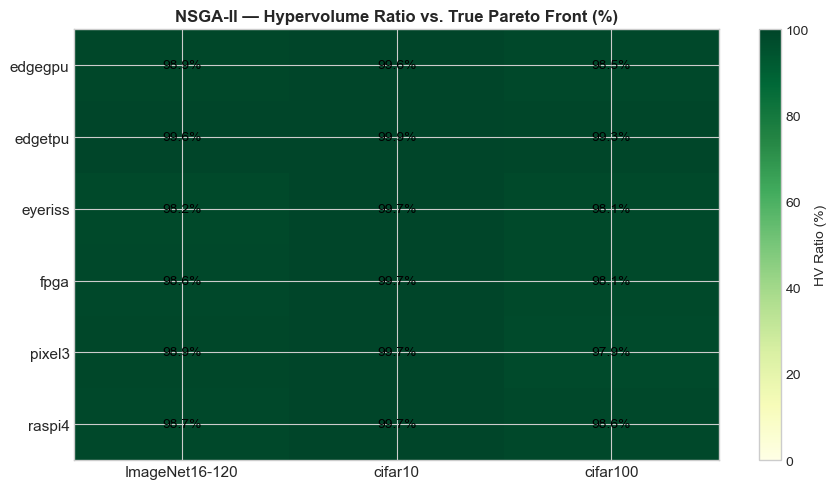

Saved: C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/nsga2_fh_multirun\heatmap_hv_nsga_ii.png


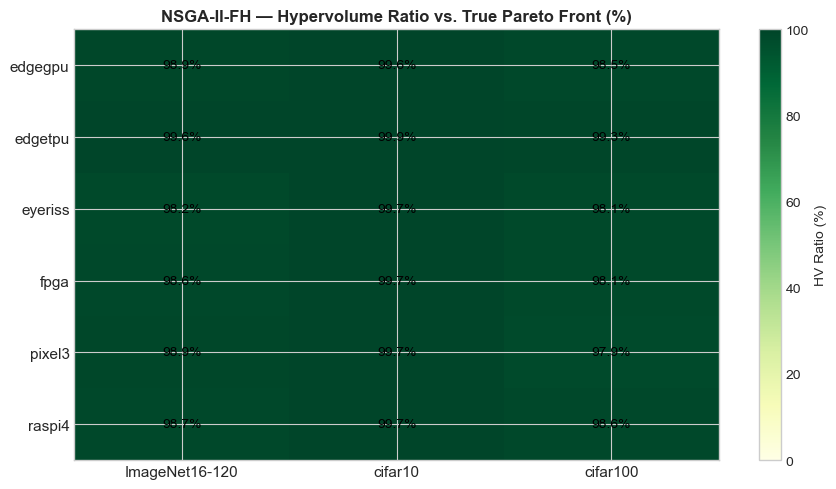

Saved: C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/nsga2_fh_multirun\heatmap_hv_nsga_ii_fh.png


In [10]:
# ── Cross-device comparison: HV ratio heatmap ─────────────────────────────────
import matplotlib.colors as mcolors

for algo in ["NSGA-II", "NSGA-II-FH"]:
    sub = summary_df[summary_df["algorithm"] == algo]
    pivot = sub.pivot(index="hw_platform", columns="dataset", values="hv_ratio_pct")

    fig, ax = plt.subplots(figsize=(9, 5))
    im = ax.imshow(pivot.values, cmap="YlGn", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, fontsize=11)
    ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels(pivot.index,   fontsize=11)
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            ax.text(j, i, f"{val:.1f}%", ha="center", va="center",
                    fontsize=10, color="black" if val > 30 else "gray")
    plt.colorbar(im, ax=ax, label="HV Ratio (%)")
    ax.set_title(f"{algo} — Hypervolume Ratio vs. True Pareto Front (%)",
                 fontsize=12, fontweight="bold")
    plt.tight_layout()
    out = os.path.join(OUTPUT_ROOT, f"heatmap_hv_{algo.replace('-','_').lower()}.png")
    plt.savefig(out, dpi=130, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}")


## 9 · Cross-Dataset Bar Chart — Pareto Front Size

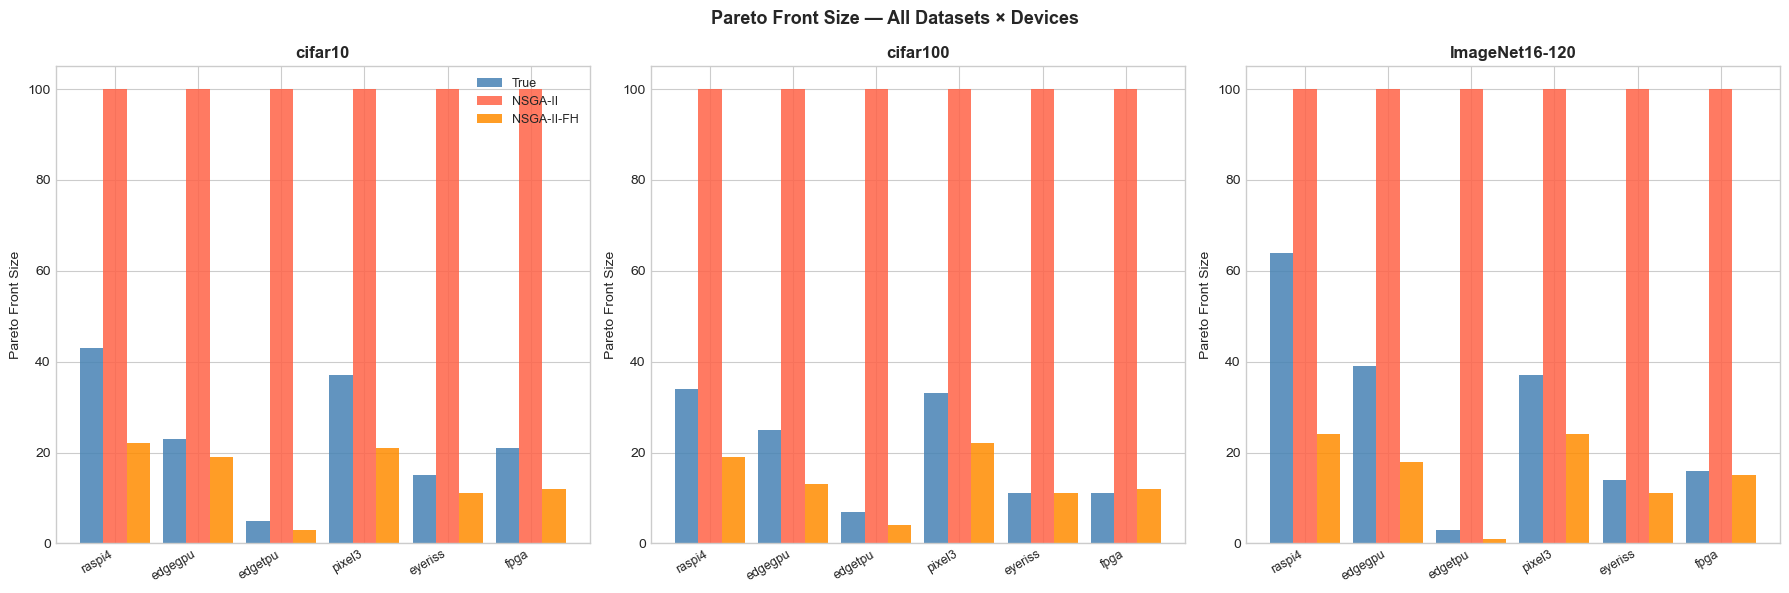

Saved: C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/nsga2_fh_multirun\barplot_pareto_size.png


In [11]:
# ── Cross-dataset bar chart: Pareto front size ────────────────────────────────
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6 * len(DATASETS), 6), sharey=False)

for ax, ds in zip(axes, DATASETS):
    sub = summary_df[summary_df["dataset"] == ds]
    devs   = HW_PLATFORMS
    x      = np.arange(len(devs))
    width  = 0.28
    colors = {"True": "steelblue", "NSGA-II": "tomato", "NSGA-II-FH": "darkorange"}
    for k, algo in enumerate(["True", "NSGA-II", "NSGA-II-FH"]):
        vals = [sub[(sub["hw_platform"] == d) & (sub["algorithm"] == algo)]["pareto_front_size"].values[0]
                for d in devs]
        ax.bar(x + k * width, vals, width, label=algo, color=colors[algo], alpha=0.85)
    ax.set_xticks(x + width); ax.set_xticklabels(devs, rotation=30, ha="right", fontsize=9)
    ax.set_title(ds, fontsize=12, fontweight="bold")
    ax.set_ylabel("Pareto Front Size")
    if ds == DATASETS[0]:
        ax.legend(fontsize=9)

plt.suptitle("Pareto Front Size — All Datasets × Devices", fontsize=13, fontweight="bold")
plt.tight_layout()
out = os.path.join(OUTPUT_ROOT, "barplot_pareto_size.png")
plt.savefig(out, dpi=130, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")


## 10 · Best Architectures per Combination (NSGA-II-FH)

In [12]:
# ── Best architectures per (dataset, device) — NSGA-II-FH ─────────────────────
best_df = (summary_df[summary_df["algorithm"] == "NSGA-II-FH"]
           [["dataset","hw_platform","best_arch_index","best_accuracy","best_latency","hv_ratio_pct"]]
           .sort_values(["dataset","best_accuracy"], ascending=[True, False])
           .reset_index(drop=True))

print("Best architectures (distance-to-ideal) — NSGA-II-FH archive")
display(best_df)
best_df.to_csv(os.path.join(OUTPUT_ROOT, "best_architectures_fh.csv"), index=False)


Best architectures (distance-to-ideal) — NSGA-II-FH archive


,dataset,hw_platform,best_arch_index,best_accuracy,best_latency,hv_ratio_pct
0,ImageNet16-120,edgetpu,8449,46.9667,-1.0000,99.61
1,ImageNet16-120,eyeriss,11973,42.9333,0.8531,98.22
2,ImageNet16-120,fpga,11973,42.9333,0.8768,98.64
3,ImageNet16-120,edgegpu,70,39.4000,1.7616,98.89
4,ImageNet16-120,raspi4,3776,37.9333,2.1917,98.70
5,ImageNet16-120,pixel3,12139,37.8000,0.8663,98.87
6,cifar10,edgetpu,10676,91.4100,1.2768,99.91
7,cifar10,eyeriss,7031,90.0700,3.3999,99.70
8,cifar10,fpga,6519,89.0500,2.3906,99.66
9,cifar10,raspi4,3157,84.4800,2.8023,99.65


## 11 · Final Aggregated Summary

In [13]:
# ── Final aggregated summary table ────────────────────────────────────────────
pivot_hv  = summary_df[summary_df["algorithm"] != "True"].pivot_table(
    index=["dataset","hw_platform"], columns="algorithm", values="hv_ratio_pct"
).round(2)
pivot_hv.columns.name = None
pivot_hv = pivot_hv.rename(columns={"NSGA-II": "HV% NSGA-II", "NSGA-II-FH": "HV% NSGA-II-FH"})

pivot_cov = summary_df[summary_df["algorithm"] != "True"].pivot_table(
    index=["dataset","hw_platform"], columns="algorithm", values="coverage_pct"
).round(2)
pivot_cov.columns.name = None
pivot_cov = pivot_cov.rename(columns={"NSGA-II": "Cov% NSGA-II", "NSGA-II-FH": "Cov% NSGA-II-FH"})

final_table = pd.concat([pivot_hv, pivot_cov], axis=1)
print("\n── Full HV Ratio & Coverage Summary (all 18 combinations) ──")
display(final_table)
final_table.to_csv(os.path.join(OUTPUT_ROOT, "final_summary_table.csv"))
print(f"\nAll outputs saved under: {OUTPUT_ROOT}")



── Full HV Ratio & Coverage Summary (all 18 combinations) ──


HV% NSGA-II  HV% NSGA-II-FH  Cov% NSGA-II  \
dataset        hw_platform                                              
ImageNet16-120 edgegpu            98.89           98.89          7.69   
               edgetpu            99.61           99.61         33.33   
               eyeriss            98.22           98.22          0.00   
               fpga               98.64           98.64          0.00   
               pixel3             98.87           98.87         10.81   
               raspi4             98.70           98.70          9.38   
cifar10        edgegpu            99.64           99.64         13.04   
               edgetpu            99.91           99.91          0.00   
               eyeriss            99.70           99.70          0.00   
               fpga               99.66           99.66          9.52   
               pixel3             99.69           99.69         21.62   
               raspi4             99.65           99.65          9.30   
cifar100       edgegpu            98.50           98.50          0.00   
               edgetpu            99.28           99.28         14.29   
               eyeriss            98.10           98.10          0.00   
               fpga               98.12           98.12          0.00   
               pixel3             97.87           97.87          9.09   
               raspi4             98.56           98.56         17.65   

                            Cov% NSGA-II-FH  
dataset        hw_platform                   
ImageNet16-120 edgegpu                 7.69  
               edgetpu                33.33  
               eyeriss                 0.00  
               fpga                    0.00  
               pixel3                 10.81  
               raspi4                  9.38  
cifar10        edgegpu                13.04  
               edgetpu                 0.00  
               eyeriss                 0.00  
               fpga                   14.29  
               pixel3                 21.62  
               raspi4                  9.30  
cifar100       edgegpu                 0.00  
               edgetpu                14.29  
               eyeriss                 0.00  
               fpga                    0.00  
               pixel3                  9.09  
               raspi4                 17.65


All outputs saved under: C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/nsga2_fh_multirun
